In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
DATA_DIR = '../data/raw'

In [2]:
try:
    df = pd.read_csv(f'{DATA_DIR}/indian_liver_patient.csv')
except UnicodeDecodeError:
    df = pd.read_csv(f'{DATA_DIR}/indian_liver_patient.csv', encoding='latin-1')

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Shape: (583, 11)
Columns: ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio', 'Dataset']


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [3]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB
None
              Age  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
count  5

In [4]:
# Original: 1 = liver patient, 2 = healthy
# Remap to: 0 = healthy, 1 = patient
print("Original target distribution:")
print(df['Dataset'].value_counts())

df['Dataset'] = df['Dataset'].map({1: 1, 2: 0})
print("\nRemapped (1=patient, 0=healthy):")
print(df['Dataset'].value_counts())

Original target distribution:
Dataset
1    416
2    167
Name: count, dtype: int64

Remapped (1=patient, 0=healthy):
Dataset
1    416
0    167
Name: count, dtype: int64


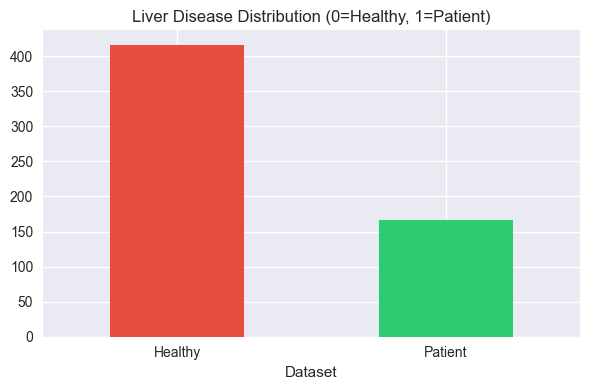

In [5]:
plt.figure(figsize=(6, 4))
df['Dataset'].value_counts().plot(kind='bar', color=['#e74c3c', '#2ecc71'])
plt.title('Liver Disease Distribution (0=Healthy, 1=Patient)')
plt.xticks([0, 1], ['Healthy', 'Patient'], rotation=0)
plt.tight_layout()
plt.savefig('../reports/eda_liver_target.png', dpi=150)
plt.show()

In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64


In [7]:
print("Gender values:", df['Gender'].unique())
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
print("After encoding:", df['Gender'].unique())

Gender values: ['Female' 'Male']
After encoding: [0 1]


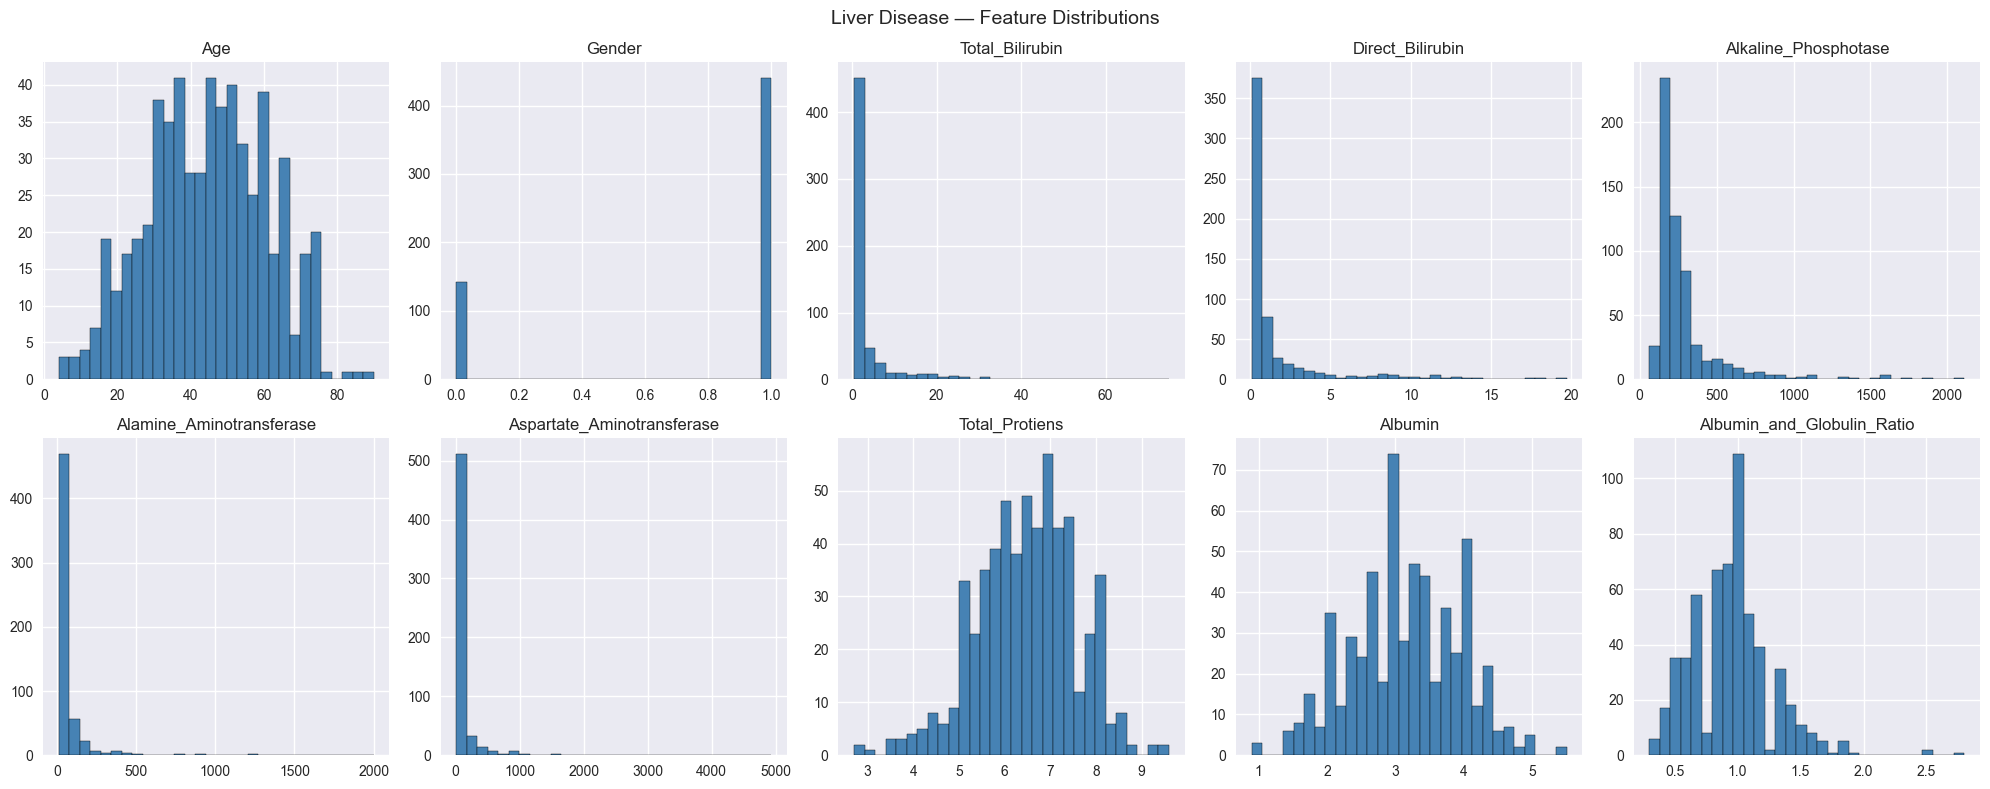

In [8]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flatten(), num_cols):
    df[col].hist(ax=ax, bins=30, color='steelblue', edgecolor='black')
    ax.set_title(col)
plt.suptitle('Liver Disease — Feature Distributions', fontsize=14)
plt.tight_layout()
plt.savefig('../reports/eda_liver_distributions.png', dpi=150)
plt.show()

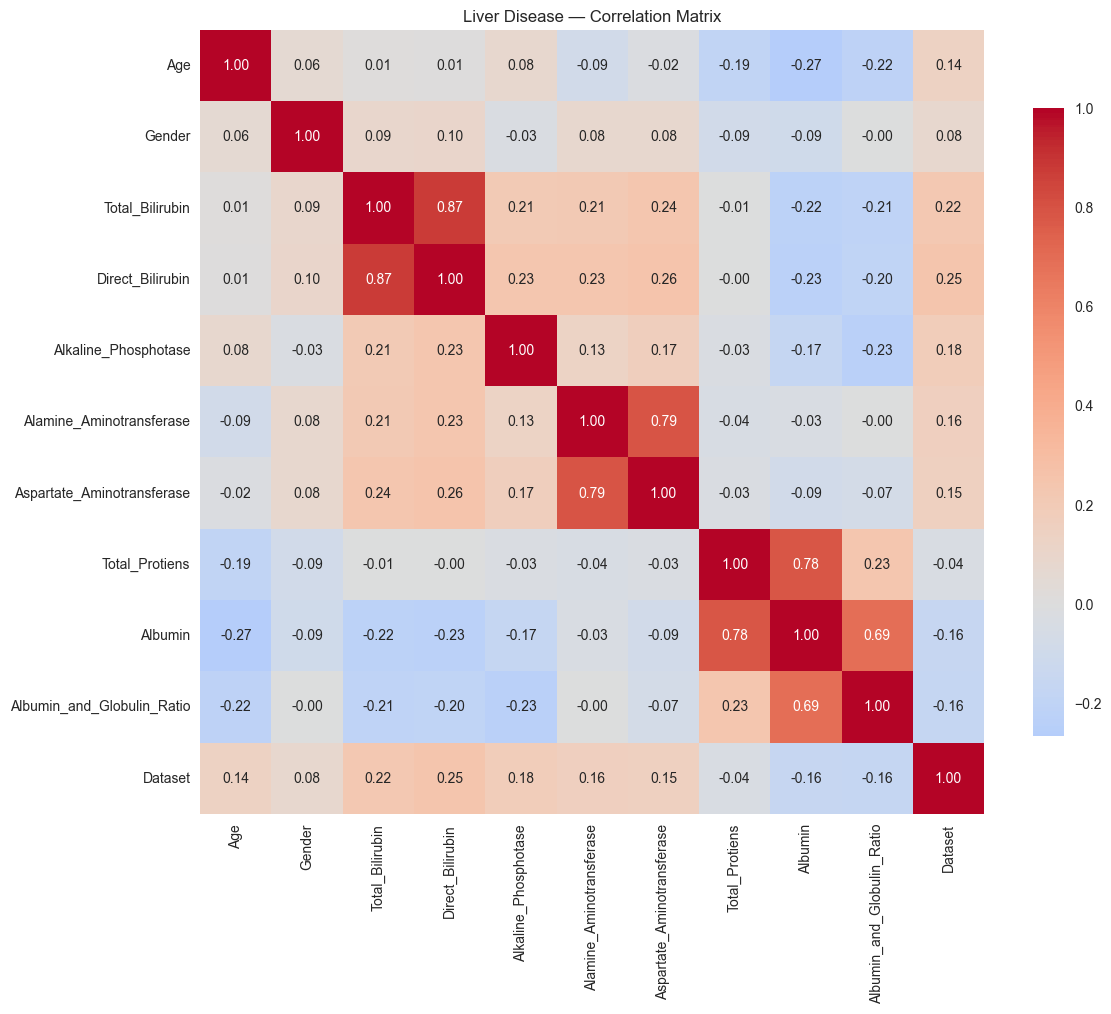


Correlations with Dataset (target):
Direct_Bilirubin              0.246046
Total_Bilirubin               0.220208
Alkaline_Phosphotase          0.184866
Alamine_Aminotransferase      0.163416
Aspartate_Aminotransferase    0.151934
Age                           0.137351
Gender                        0.082416
Total_Protiens               -0.035008
Albumin                      -0.161388
Albumin_and_Globulin_Ratio   -0.163131
Name: Dataset, dtype: float64


In [9]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Liver Disease — Correlation Matrix')
plt.tight_layout()
plt.savefig('../reports/eda_liver_correlation.png', dpi=150)
plt.show()

print("\nCorrelations with Dataset (target):")
print(df.corr()['Dataset'].drop('Dataset').sort_values(ascending=False))

In [10]:
import os
os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/liver_clean.csv', index=False)
print(f"✅ Saved liver_clean.csv — shape: {df.shape}")

✅ Saved liver_clean.csv — shape: (583, 11)


## 📊 EDA Summary — Indian Liver Patient

### Key Findings
- **583 samples**, 10 features, binary target
- **Class imbalance:** 71% patient, 29% healthy → **SMOTE needed**
- **4 missing values** in Albumin_and_Globulin_Ratio → impute with median
- **Gender** categorical → encode (Male=1, Female=0)

### Top Predictors (from correlation with target)
1. **Alkaline_Phosphotase** — strong positive
2. **Alamine_Aminotransferase** (ALT) — positive
3. **Aspartate_Aminotransferase** (AST) — positive
4. **Total_Bilirubin** — positive
5. **Albumin** — negative (higher albumin = healthier)

### Preprocessing Decisions
- Remap target: 2 → 0 (so 1 = disease)
- Encode Gender
- Impute 4 missing with median
- SMOTE for class imbalance
- StandardScaler (bilirubin values are orders of magnitude larger than albumin)
